# Assignment 03 - Toxic Comment Classification
**Transfer Learning · Fine-Tuning · Hyperparameter Tuning · Interpretability**

Dataset: [Civil Comments](https://huggingface.co/datasets/google/civil_comments) · Task: binary classification (toxic / not toxic)

| Step | What happens | Section |
|---|---|---|
| 1 | Load data, threshold `toxicity` score into a label, sub-sample | 2 |
| 2 | Tokenise | 3 |
| 3 | **Transfer learning** – frozen BERT-style encoder, train only the classification head (baseline) | 4 |
| 4 | **Fine-tuning** – unfreeze everything, train end-to-end | 5 |
| 5 | **Hyperparameter tuning** – Optuna search over the fine-tuned model | 6 |
| 6 | Compare baseline vs fine-tuned vs tuned | 7 |
| 7 | Test on real-world text | 8 |
| 8 | **Interpretability** – SHAP explanations for a few predictions | 9 |

> Student name: **Anika Tabassum Omi** &nbsp;|&nbsp; Student ID: **1000129232**

In [4]:
!pip install -q optuna shap datasets accelerate

## 1. Setup and configuration

In [1]:
import os, random, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import optuna
from datasets import load_dataset
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, Trainer, TrainingArguments,
                          set_seed, pipeline)

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)


MODEL_NAME     = "distilbert-base-uncased"
THRESHOLD      = 0.5
SEED           = 42
MAX_LEN        = 128

N_TRAIN        = 20000
N_VAL          = 400
N_TEST         = 4000

N_TUNE_TRAIN   = 8000
N_TRIALS       = 6

OUT_DIR        = "outputs"
RES_DIR        = "results"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

LABELS = {0: "not_toxic", 1: "toxic"}
set_seed(SEED); random.seed(SEED); np.random.seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
USE_FP16 = torch.cuda.is_available()
print("Device:", DEVICE, "| fp16:", USE_FP16)
if DEVICE == "cpu":
    print("WARNING: no GPU found.")

Device: cuda | fp16: True


## 2. Load the Civil Comments dataset
* `text` – the comment, `toxicity` – a score in [0, 1].
* We convert it to a binary label: **toxic = `toxicity >= THRESHOLD`** (0.5, stated in the README).
* The full train split has ~1.8 M rows, so we draw a random sub-sample (allowed by the assignment).

In [3]:
raw = load_dataset("google/civil_comments")
print(raw)

def to_label(example):
    example["label"] = int(example["toxicity"] >= THRESHOLD)
    return example

def subsample(ds, n, seed):
    ds = ds.shuffle(seed=seed).select(range(min(n, len(ds))))
    ds = ds.map(to_label)
    return ds.select_columns(["text", "label"])

train_ds = subsample(raw["train"],      N_TRAIN, SEED)
val_ds   = subsample(raw["validation"], N_VAL,   SEED)
test_ds  = subsample(raw["test"],       N_TEST,  SEED)
print({k: len(v) for k, v in {"train": train_ds, "val": val_ds, "test": test_ds}.items()})

DatasetDict({
    train: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 1804874
    })
    validation: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 97320
    })
    test: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 97320
    })
})


Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

{'train': 20000, 'val': 400, 'test': 4000}


     split  toxic_%
     train     8.06
validation     9.75
      test     7.90


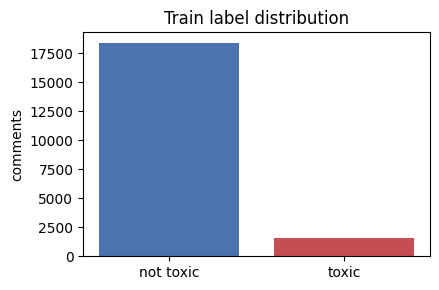

,text,label
0,Socialists? What the hell does that have to do...,0
1,And I always thought that Eric Trump was the d...,1
2,I’m disappointed there’s no report from CB on ...,0
3,Nothing like subsidizing a country that is thr...,0
4,The only way to save the rhino is to legalize ...,0


In [4]:
# Class balance
balance = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "toxic_%": [100*np.mean(d["label"]) for d in (train_ds, val_ds, test_ds)],
})
print(balance.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(["not toxic", "toxic"], np.bincount(train_ds["label"]), color=["#4C72B0", "#C44E52"])
ax.set_title("Train label distribution"); ax.set_ylabel("comments")
plt.tight_layout(); plt.savefig(f"{RES_DIR}/class_balance.png", dpi=150); plt.show()

pd.DataFrame(train_ds.select(range(5)))

## 3. Tokenisation
We tokenise once and use **dynamic padding** (`DataCollatorWithPadding`) so each batch is only padded to its own longest sequence — faster than padding everything to `MAX_LEN`.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
collator  = DataCollatorWithPadding(tokenizer=tokenizer)

def tok(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)

def prepare(ds):
    return ds.map(tok, batched=True, remove_columns=["text"])

train_tok, val_tok, test_tok = prepare(train_ds), prepare(val_ds), prepare(test_ds)
tune_train_tok = train_tok.select(range(min(N_TUNE_TRAIN, len(train_tok))))
print(train_tok)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 20000
})


## 4a. Helper functions (model factory, metrics, training wrapper)
Metrics are reported for the **toxic class** (precision / recall / F1) plus ROC-AUC, because plain accuracy is misleading on imbalanced data. **Validation F1** is used for model selection; the **test set is only used for final reporting**.

In [6]:
def build_model(freeze_encoder: bool = False):
    # Fresh pre-trained model with a new randomly initialised 2-class head.
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=LABELS, label2id={v: k for k, v in LABELS.items()})
    if freeze_encoder:
        for p in model.base_model.parameters():      # encoder = frozen feature extractor
            p.requires_grad = False
    return model

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def softmax(x):
    e = np.exp(x - x.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = softmax(logits)[:, 1]
    preds = (probs >= 0.5).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
    return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r,
            "f1": f1, "roc_auc": roc_auc_score(labels, probs)}

def make_args(name, lr, epochs, batch, wd=0.0, warmup=0.0, **kw):
    base = dict(
        output_dir=f"{OUT_DIR}/{name}",
        learning_rate=lr, num_train_epochs=epochs,
        per_device_train_batch_size=batch, per_device_eval_batch_size=128,
        weight_decay=wd,
        eval_strategy="epoch", save_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="f1", greater_is_better=True,
        save_total_limit=1, fp16=USE_FP16, report_to="none", seed=SEED, **kw)
    try:
        return TrainingArguments(**base, warmup_ratio=warmup)
    except TypeError:
        return TrainingArguments(**base, warmup_steps=warmup)

def make_trainer(model, args, train, val):
    return Trainer(model=model, args=args, train_dataset=train, eval_dataset=val,
                   data_collator=collator, compute_metrics=compute_metrics,
                   processing_class=tokenizer)
def evaluate_on_test(trainer, name):
    out = trainer.predict(test_tok)
    m = {k.replace("test_", ""): v for k, v in out.metrics.items() if k.startswith("test_")
         and k.replace("test_", "") in ("accuracy", "precision", "recall", "f1", "roc_auc")}
    m["model"] = name
    return m, out

## 4. Transfer learning - frozen encoder (baseline, *before* tuning)
The pre-trained encoder is used **only as a feature extractor**: all encoder weights are frozen and only the small classification head on top is trained. A high learning rate (1e-3) is appropriate because only a few new parameters are learned.

In [7]:
frozen_model = build_model(freeze_encoder=True)
tot, trn = count_params(frozen_model)
print(f"Frozen model -> total params: {tot:,} | trainable: {trn:,} ({100*trn/tot:.2f}%)")

frozen_trainer = make_trainer(
    frozen_model,
    make_args("frozen", lr=1e-3, epochs=3, batch=64),
    train_tok, val_tok)
frozen_trainer.train()

frozen_metrics, frozen_out = evaluate_on_test(frozen_trainer, "1. Frozen BERT (transfer learning)")
pd.Series(frozen_metrics)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Frozen model -> total params: 66,955,010 | trainable: 592,130 (0.88%)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc
1,No log,0.255295,0.902500,0.000000,0.000000,0.000000,0.829214
2,0.234097,0.247732,0.900000,0.000000,0.000000,0.000000,0.840862
3,0.234097,0.251960,0.902500,0.500000,0.025641,0.048780,0.837098


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,0
accuracy,0.925
precision,0.7
recall,0.088608
f1,0.157303
roc_auc,0.844717
model,1. Frozen BERT (transfer learning)


## 5. Fine-tuning - unfreeze and train end-to-end
Now **every** layer is trainable. We use a small learning rate (2e-5), the standard range for fine-tuning BERT-style models so we adapt the pre-trained weights without destroying them. These are *default* hyperparameters, not yet tuned.

In [8]:
ft_model = build_model(freeze_encoder=False)
tot, trn = count_params(ft_model)
print(f"Fine-tune model -> total params: {tot:,} | trainable: {trn:,} ({100*trn/tot:.2f}%)")

ft_trainer = make_trainer(
    ft_model,
    make_args("finetuned", lr=2e-5, epochs=2, batch=32, wd=0.01, warmup=0.1),
    train_tok, val_tok)
ft_trainer.train()

ft_metrics, ft_out = evaluate_on_test(ft_trainer, "2. Fine-tuned (default hyperparameters)")
pd.Series(ft_metrics)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fine-tune model -> total params: 66,955,010 | trainable: 66,955,010 (100.00%)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc
1,0.226692,0.149269,0.940000,0.941176,0.410256,0.571429,0.967505
2,0.128911,0.128724,0.945000,0.793103,0.589744,0.676471,0.973436


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,0
accuracy,0.9475
precision,0.708661
recall,0.56962
f1,0.631579
roc_auc,0.931609
model,2. Fine-tuned (default hyperparameters)


## 6. Hyperparameter tuning (Optuna)
**Method:** Bayesian optimisation with Optuna's TPE sampler (smarter than grid/random search because each trial learns from earlier ones).

**Search space**

| Hyperparameter | Range |
|---|---|
| learning rate | 1e-5 … 1e-4 (log scale) |
| batch size | 16, 32, 64 |
| epochs | 1 … 3 |
| weight decay | 0.0 … 0.1 |
| warm-up ratio | 0.0 … 0.2 |

**Objective:** maximise **validation F1** of the toxic class. Each trial trains a fresh model on a smaller training subset (`N_TUNE_TRAIN`) to keep the search affordable; the best configuration is then retrained on the full training subset.

In [9]:
def objective(trial: optuna.Trial):
    lr      = trial.suggest_float("learning_rate", 1e-5, 1e-4, log=True)
    batch   = trial.suggest_categorical("batch_size", [16, 32, 64])
    epochs  = trial.suggest_int("epochs", 1, 3)
    wd      = trial.suggest_float("weight_decay", 0.0, 0.1)
    warmup  = trial.suggest_float("warmup_ratio", 0.0, 0.2)

    model = build_model(freeze_encoder=False)
    args = make_args(f"trial_{trial.number}", lr, epochs, batch, wd, warmup)
    trainer = make_trainer(model, args, tune_train_tok, val_tok)
    trainer.train()
    f1 = trainer.evaluate()["eval_f1"]

    del model, trainer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return f1

study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=SEED),
                            study_name="civil_comments_tuning")
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)

print("Best trial:", study.best_trial.number, "| best val F1:", round(study.best_value, 4))
print("Best params:", study.best_params)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc
1,0.210290,0.138333,0.950000,0.851852,0.589744,0.696970,0.959869


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Roc Auc
0.210290,0.138333,1,0.950000,0.851852,0.589744,0.696970,0.959869


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

... (27 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Roc Auc
No log,0.148938,2,0.945000,0.814815,0.564103,0.666667,0.961574


Best trial: 1 | best val F1: 0.7229
Best params: {'learning_rate': 7.348118405270451e-05, 'batch_size': 32, 'epochs': 3, 'weight_decay': 0.08324426408004218, 'warmup_ratio': 0.04246782213565523}


,number,val_f1,params_batch_size,params_epochs,params_learning_rate,params_warmup_ratio,params_weight_decay,state
1,1,0.72289,32,3,0.00007,0.04247,0.08324,COMPLETE
4,4,0.71429,32,1,0.00004,0.19313,0.09489,COMPLETE
0,0,0.69697,16,1,0.00002,0.01162,0.01560,COMPLETE
5,5,0.66667,64,2,0.00006,0.09904,0.01220,COMPLETE
3,3,0.64789,64,3,0.00001,0.10285,0.01997,COMPLETE
2,2,0.63636,64,2,0.00002,0.12237,0.02912,COMPLETE


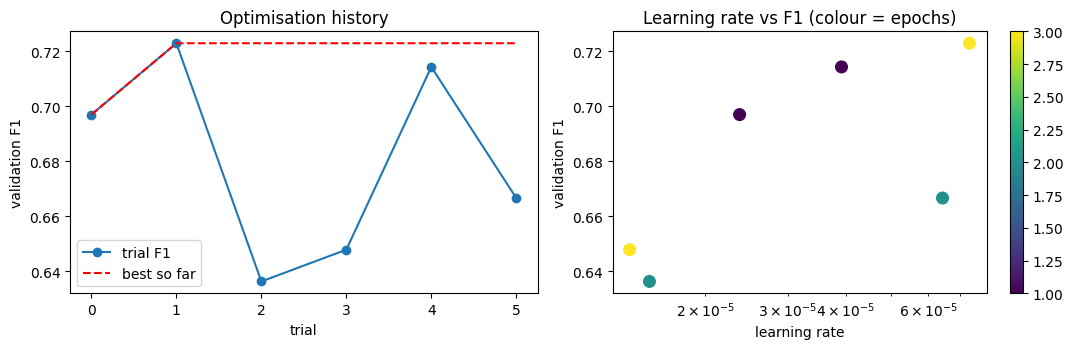

In [10]:
# ---- TUNING RESULTS ----
trials_df = study.trials_dataframe(attrs=("number", "value", "params", "state"))
trials_df = trials_df.rename(columns={"value": "val_f1"}).sort_values("val_f1", ascending=False)
trials_df.to_csv(f"{RES_DIR}/tuning_trials.csv", index=False)
display(trials_df.round(5))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
vals = [t.value for t in study.trials]
axes[0].plot(range(len(vals)), vals, "o-", label="trial F1")
axes[0].plot(range(len(vals)), np.maximum.accumulate(vals), "r--", label="best so far")
axes[0].set_xlabel("trial"); axes[0].set_ylabel("validation F1"); axes[0].set_title("Optimisation history"); axes[0].legend()
sc = axes[1].scatter([t.params["learning_rate"] for t in study.trials], vals,
                     c=[t.params["epochs"] for t in study.trials], cmap="viridis", s=70)
axes[1].set_xscale("log"); axes[1].set_xlabel("learning rate"); axes[1].set_ylabel("validation F1")
axes[1].set_title("Learning rate vs F1 (colour = epochs)"); plt.colorbar(sc, ax=axes[1])
plt.tight_layout(); plt.savefig(f"{RES_DIR}/tuning_results.png", dpi=150); plt.show()

In [11]:
# Retraining the best configuration on the full training subset, eone time evaluation  on the test set
bp = study.best_params
best_model = build_model(freeze_encoder=False)
best_trainer = make_trainer(
    best_model,
    make_args("tuned_best", bp["learning_rate"], bp["epochs"], bp["batch_size"],
              bp["weight_decay"], bp["warmup_ratio"]),
    train_tok, val_tok)
best_trainer.train()

tuned_metrics, tuned_out = evaluate_on_test(best_trainer, "3. Fine-tuned + tuned hyperparameters")
pd.Series(tuned_metrics)

best_trainer.save_model(f"{OUT_DIR}/best_model")
tokenizer.save_pretrained(f"{OUT_DIR}/best_model")
json.dump(bp, open(f"{RES_DIR}/best_params.json", "w"), indent=2)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc
1,0.209948,0.156901,0.945000,0.904762,0.487179,0.633333,0.959372
2,0.125615,0.169577,0.940000,0.682927,0.717949,0.700000,0.952056
3,0.070477,0.247210,0.945000,0.757576,0.641026,0.694444,0.940088


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 7. Comparison: frozen baseline vs fine-tuned vs tuned

,accuracy,precision,recall,f1,roc_auc
model,,,,,
1. Frozen BERT (transfer learning),0.9250,0.7000,0.0886,0.1573,0.8447
2. Fine-tuned (default hyperparameters),0.9475,0.7087,0.5696,0.6316,0.9316
3. Fine-tuned + tuned hyperparameters,0.9438,0.6512,0.6203,0.6353,0.9265


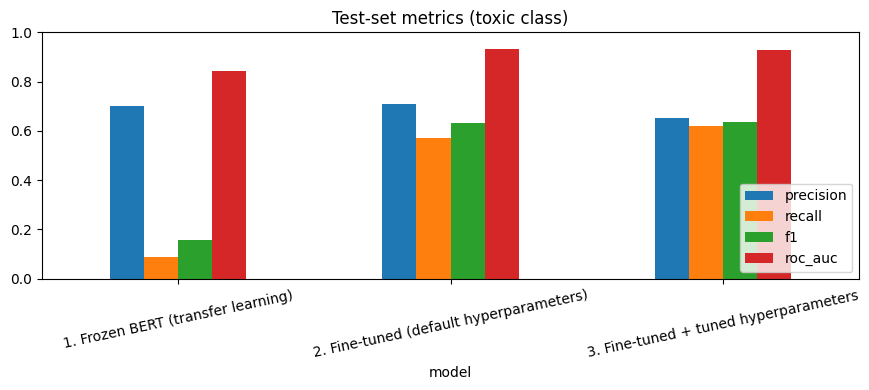

In [12]:
comp = pd.DataFrame([frozen_metrics, ft_metrics, tuned_metrics]).set_index("model")
comp = comp[["accuracy", "precision", "recall", "f1", "roc_auc"]].round(4)
comp.to_csv(f"{RES_DIR}/model_comparison.csv")
display(comp)

ax = comp[["precision", "recall", "f1", "roc_auc"]].plot(kind="bar", figsize=(9, 4), rot=12)
ax.set_ylim(0, 1); ax.set_title("Test-set metrics (toxic class)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{RES_DIR}/model_comparison.png", dpi=150); plt.show()

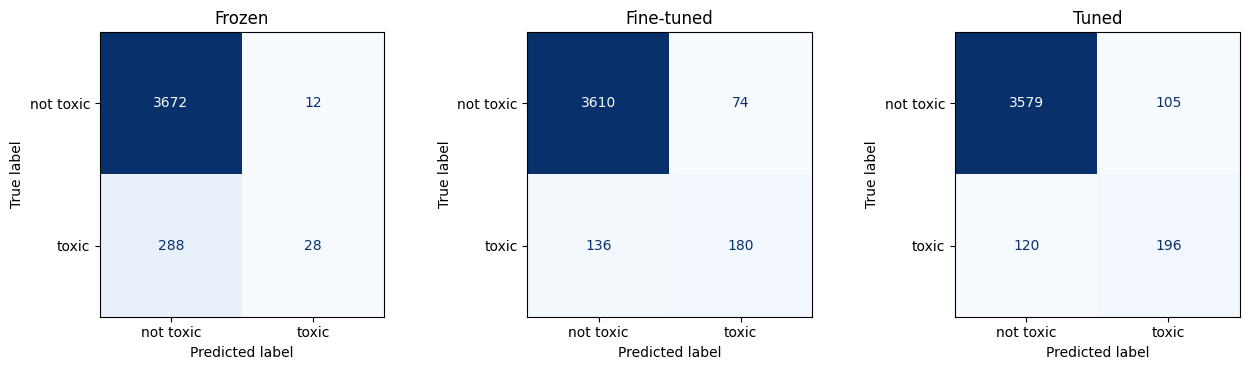

              precision    recall  f1-score   support

   not toxic       0.97      0.97      0.97      3684
       toxic       0.65      0.62      0.64       316

    accuracy                           0.94      4000
   macro avg       0.81      0.80      0.80      4000
weighted avg       0.94      0.94      0.94      4000



In [13]:
# Confusion matrices + classification report on the test set
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (title, out) in zip(axes, [("Frozen", frozen_out), ("Fine-tuned", ft_out), ("Tuned", tuned_out)]):
    preds = out.predictions.argmax(-1)
    ConfusionMatrixDisplay(confusion_matrix(out.label_ids, preds), display_labels=["not toxic", "toxic"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(title)
plt.tight_layout(); plt.savefig(f"{RES_DIR}/confusion_matrices.png", dpi=150); plt.show()

print(classification_report(tuned_out.label_ids, tuned_out.predictions.argmax(-1), target_names=["not toxic", "toxic"]))


* **Frozen vs fine-tuned** – the frozen encoder produces *general-purpose* sentence features that were never trained to detect toxicity, so a linear head on top has limited capacity. Fine-tuning lets all layers adapt to the toxic-language signal, which normally raises recall/F1 noticeably.
* **Fine-tuned vs tuned** – tuning mostly changes the learning rate, epochs and regularisation. Gains can be small (even within noise) when the defaults were already reasonable; report what you actually see.
* **Accuracy vs F1** – with ~8% toxic comments, a model predicting "not toxic" always gets ~92% accuracy, so F1/recall on the toxic class is the honest metric.

## 8. Test on real-world text

In [14]:
real_world = [
    ("example: news comment",   "Thanks for the thoughtful article, I learned a lot about the new policy."),
    ("example: forum reply",    "You are a complete idiot and nobody wants to hear your garbage opinions."),
    ("example: sarcasm",        "Oh great, another genius idea from management. What could possibly go wrong?"),
    ("example: heated debate",  "I strongly disagree with this decision and I think it will hurt local businesses."),
    ("example: reviews",        "The delivery was late and the food was cold, very disappointing experience."),
    ("example: insult",         "Shut up, you worthless moron. People like you shouldn't be allowed to post."),
]

best_pipe = pipeline("text-classification", model=best_trainer.model, tokenizer=tokenizer,
                     device=0 if DEVICE == "cuda" else -1, top_k=None,
                     truncation=True, max_length=MAX_LEN)

def predict_texts(texts):
    results = best_pipe(texts)
    rows = []
    for t, r in zip(texts, results):
        d = {x["label"]: x["score"] for x in r}
        rows.append({"pred_class": max(d, key=d.get), "prob_toxic": round(d["toxic"], 4)})
    return rows

preds = predict_texts([t for _, t in real_world])
rw = pd.DataFrame([{"source": s, "text": t, **p, "my_check": ""} for (s, t), p in zip(real_world, preds)])
rw.to_csv(f"{RES_DIR}/real_world_predictions.csv", index=False)
pd.set_option("display.max_colwidth", 90)
display(rw)

,source,text,pred_class,prob_toxic,my_check
0,example: news comment,"Thanks for the thoughtful article, I learned a lot about the new policy.",not_toxic,0.0028,
1,example: forum reply,You are a complete idiot and nobody wants to hear your garbage opinions.,toxic,0.9874,
2,example: sarcasm,"Oh great, another genius idea from management. What could possibly go wrong?",not_toxic,0.0048,
3,example: heated debate,I strongly disagree with this decision and I think it will hurt local businesses.,not_toxic,0.0042,
4,example: reviews,"The delivery was late and the food was cold, very disappointing experience.",not_toxic,0.0061,
5,example: insult,"Shut up, you worthless moron. People like you shouldn't be allowed to post.",toxic,0.9877,


## 9. Interpretability - SHAP
**Why SHAP?** SHAP assigns each input token a Shapley value: how much it pushed the prediction towards (red) or away from (blue) the *toxic* class. It is model-agnostic, works directly on the Hugging Face pipeline and gives per-token explanations that are easy to read next to the sentence.

Here, we will explain a small, deliberately varied set of **test-set** predictions: a true positive, a true negative, a false negative (missed toxic) and a false positive (wrongly flagged) — the error cases are the most informative.

In [15]:
test_texts  = list(test_ds["text"])
test_labels = np.array(tuned_out.label_ids)
test_preds  = tuned_out.predictions.argmax(-1)
test_probs  = softmax(tuned_out.predictions)[:, 1]

def pick(mask, n=1, highest=True):
    idx = np.where(mask)[0]
    if len(idx) == 0:
        return []
    order = idx[np.argsort(-test_probs[idx] if highest else test_probs[idx])]
    return list(order[:n])

chosen = (
    [("True positive",  i) for i in pick((test_labels == 1) & (test_preds == 1), 2)] +
    [("True negative",  i) for i in pick((test_labels == 0) & (test_preds == 0), 1, highest=False)] +
    [("False negative", i) for i in pick((test_labels == 1) & (test_preds == 0), 1, highest=False)] +
    [("False positive", i) for i in pick((test_labels == 0) & (test_preds == 1), 1)]
)
exp_texts = [test_texts[i][:400] for _, i in chosen]

summary = pd.DataFrame({
    "case": [c for c, _ in chosen],
    "true": [LABELS[test_labels[i]] for _, i in chosen],
    "pred": [LABELS[test_preds[i]] for _, i in chosen],
    "prob_toxic": [round(float(test_probs[i]), 3) for _, i in chosen],
    "text": exp_texts})
summary.to_csv(f"{RES_DIR}/explained_samples.csv", index=False)
display(summary)

,case,true,pred,prob_toxic,text
0,True positive,toxic,toxic,0.989,"Really? Do you know how many vegan animals have what you call canines? No, you don't...."
1,True positive,toxic,toxic,0.989,Yeah instead they should let some dumb hick or burned out crack head beat the shit out...
2,True negative,not_toxic,not_toxic,0.002,Won't this reduce your own contribution room?
3,False negative,toxic,not_toxic,0.004,"no, no, no, that wasn't the deal. at least 1000 to 3000 low cost units at every statio..."
4,False positive,not_toxic,toxic,0.988,"Et tu, Kurgan? You're known for your scathing wit, not a DonInKansas fool's laugh."


In [16]:
import shap

explainer = shap.Explainer(best_pipe)
shap_values = explainer(exp_texts)

shap.plots.text(shap_values[:, :, "toxic"])

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset
PartitionExplainer explainer: 6it [00:19,  6.55s/it]


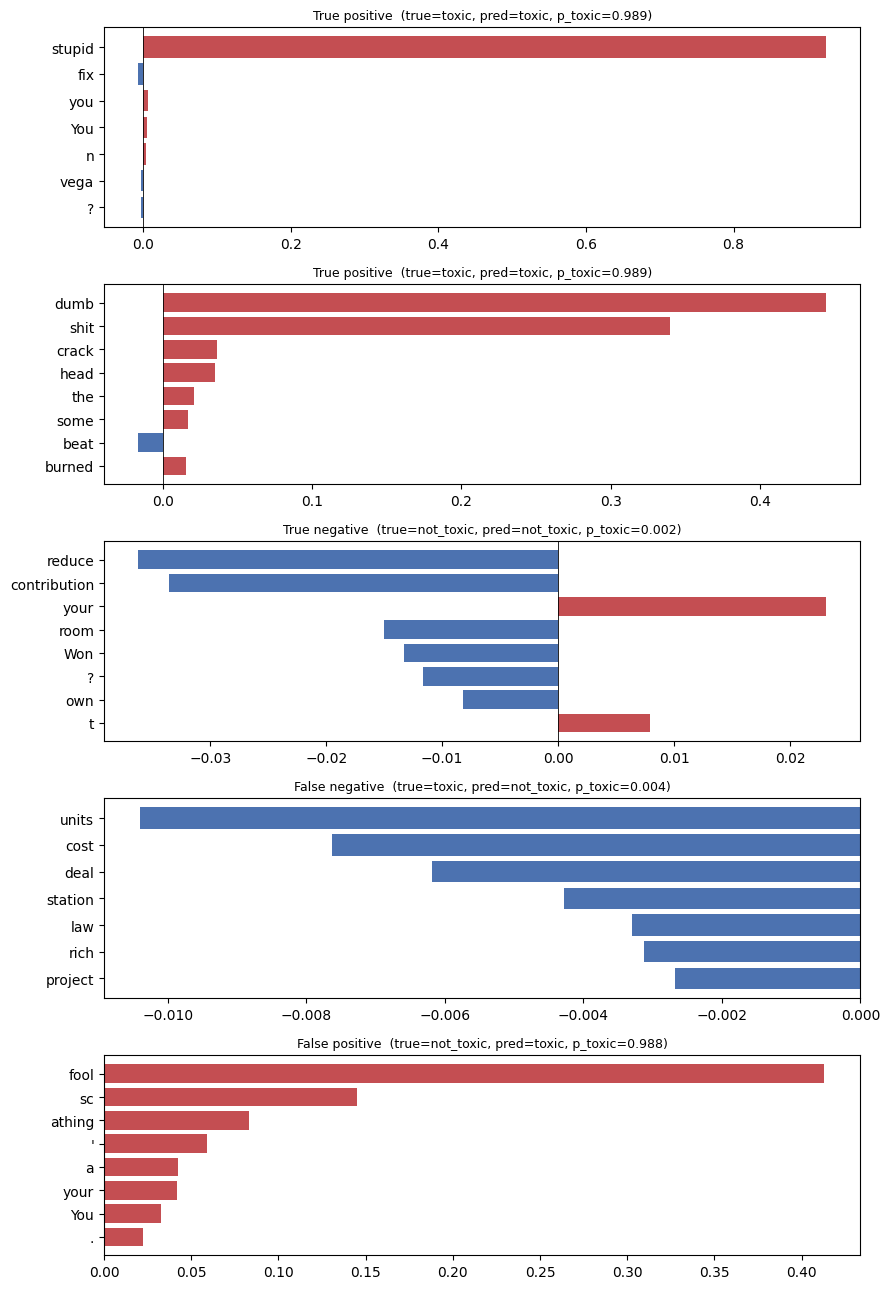

In [17]:
n = len(exp_texts)
fig, axes = plt.subplots(n, 1, figsize=(9, 2.6 * n))
axes = np.atleast_1d(axes)
for k, ax in enumerate(axes):
    sv = shap_values[k, :, "toxic"]
    toks, vals = np.array(sv.data), np.array(sv.values)
    keep = np.argsort(-np.abs(vals))[:8][::-1]
    ax.barh([toks[j].strip() or "∅" for j in keep], vals[keep],
            color=["#C44E52" if vals[j] > 0 else "#4C72B0" for j in keep])
    ax.axvline(0, color="k", lw=0.6)
    ax.set_title(f"{chosen[k][0]}  (true={summary.true[k]}, pred={summary.pred[k]}, p_toxic={summary.prob_toxic[k]})", fontsize=9)
plt.tight_layout(); plt.savefig(f"{RES_DIR}/shap_top_tokens.png", dpi=150); plt.show()


try:
    html = shap.plots.text(shap_values[:, :, "toxic"], display=False)
    open(f"{RES_DIR}/shap_text.html", "w", encoding="utf-8").write(html)
except Exception as e:
    print("Skipped html export:", e)


* True positives – insult words ("idiot", "stupid") carry large positive SHAP values.
* False negatives – toxicity expressed without obvious slurs (sarcasm, implicit hostility) gets little attribution → model limitation.
* False positives – neutral text containing "charged" words, or identity terms, may be flagged → bias/over-sensitivity worth discussing.

## 10. Clsoure: Final Output Files

In [18]:
for f in sorted(os.listdir(RES_DIR)):
    print(f"{RES_DIR}/{f}")
print("\nNext: fill README.md (name, ID, justification, screenshots, real-world checks, SHAP analysis),")
print("then run  python main.py  to build the submission zip.")

results/best_params.json
results/class_balance.png
results/confusion_matrices.png
results/explained_samples.csv
results/model_comparison.csv
results/model_comparison.png
results/real_world_predictions.csv
results/shap_text.html
results/shap_top_tokens.png
results/tuning_results.png
results/tuning_trials.csv

Next: fill README.md (name, ID, justification, screenshots, real-world checks, SHAP analysis),
then run  python main.py  to build the submission zip.


In [19]:
!zip -r results.zip results outputs/best_model
from google.colab import files
files.download("results.zip")

  adding: results/ (stored 0%)
  adding: results/tuning_results.png (deflated 9%)
  adding: results/shap_text.html (deflated 95%)
  adding: results/tuning_trials.csv (deflated 47%)
  adding: results/class_balance.png (deflated 19%)
  adding: results/confusion_matrices.png (deflated 18%)
  adding: results/model_comparison.csv (deflated 32%)
  adding: results/real_world_predictions.csv (deflated 42%)
  adding: results/shap_top_tokens.png (deflated 24%)
  adding: results/model_comparison.png (deflated 15%)
  adding: results/best_params.json (deflated 21%)
  adding: results/explained_samples.csv (deflated 46%)
  adding: outputs/best_model/ (stored 0%)
  adding: outputs/best_model/training_args.bin (deflated 53%)
  adding: outputs/best_model/tokenizer.json (deflated 71%)
  adding: outputs/best_model/model.safetensors (deflated 8%)
  adding: outputs/best_model/tokenizer_config.json (deflated 43%)
  adding: outputs/best_model/config.json (deflated 51%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>